In [190]:
# === Libraries ===
import pandas as pd
import numpy as np

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import StandardScaler

# modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV

# clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [191]:
file_path = r"C:\Users\carnival\Downloads\student-mat.csv"
df = pd.read_csv(file_path, sep=';')
print("Shape:", df.shape)
df.head()


Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [192]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers} outliers")


age: 1 outliers
Medu: 0 outliers
Fedu: 2 outliers
traveltime: 8 outliers
studytime: 27 outliers
failures: 83 outliers
famrel: 26 outliers
freetime: 19 outliers
goout: 0 outliers
Dalc: 18 outliers
Walc: 0 outliers
health: 0 outliers
absences: 15 outliers
G1: 0 outliers
G2: 13 outliers
G3: 0 outliers


In [193]:
Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['absences'] = np.where(df['absences'] > upper, upper,
                          np.where(df['absences'] < lower, lower, df['absences']))


## Exploratory Data Analysis (EDA)

In this section, we explore the dataset to understand distributions, relationships, and potential drivers of student performance.  
We focus on descriptive statistics, correlations, group comparisons, and hypothesis testing.


In [194]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


### Descriptive Statistics – Key Insights

- **Age:** Most students are between 16–18 years old (mean ≈ 16.7, max = 22).  
- **Parental Education (Medu, Fedu):** On average, parents have medium education (≈ 2.5–2.7 on scale 0–4).  
- **Study Time:** Median = 2 (which corresponds to 2–5 hours/week), showing limited study effort.  
- **Failures:** Most students have no past class failures (median = 0), but some have up to 3.  
- **Absences:** Average absences ≈ 5, but some students missed up to 20 classes.  
- **Grades:**  
  - G1 mean = 10.9, G2 mean = 10.7, G3 mean = 10.4.  
  - Distribution shows decline from G1 to G3, suggesting some students drop in performance over the year.  


In [195]:
df.info()
df.duplicated().sum()
df.isnull().sum()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      395 non-null    object 
 1   sex         395 non-null    object 
 2   age         395 non-null    int64  
 3   address     395 non-null    object 
 4   famsize     395 non-null    object 
 5   Pstatus     395 non-null    object 
 6   Medu        395 non-null    int64  
 7   Fedu        395 non-null    int64  
 8   Mjob        395 non-null    object 
 9   Fjob        395 non-null    object 
 10  reason      395 non-null    object 
 11  guardian    395 non-null    object 
 12  traveltime  395 non-null    int64  
 13  studytime   395 non-null    int64  
 14  failures    395 non-null    int64  
 15  schoolsup   395 non-null    object 
 16  famsup      395 non-null    object 
 17  paid        395 non-null    object 
 18  activities  395 non-null    object 
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.187342,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,5.694448,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,20.000000,19.000000,19.000000,20.000000


## Data Quality Report

- **Schema & Data Types:**  
  The dataset contains 395 rows and 33 columns.  
  - 16 numerical features (e.g., `age`, `Medu`, `studytime`, `G1`, `G2`, `G3`).  
  - 17 categorical features (e.g., `school`, `sex`, `address`, `Mjob`, `Fjob`).  
  Data types are consistent and correctly assigned.

- **Duplicates:**  
  0 duplicate rows were detected → no action required.

- **Missing Values:**  
  All columns have 100% non-null values. No imputation needed.

- **Outliers:**  
  Using the IQR method, outliers were mainly detected in the `absences` column, where a few students show extremely high absence counts compared to the majority.  
  Decision: we will cap these extreme values (winsorization) to reduce their effect on models.

- **Overall Data Quality:**  
  The dataset is of good quality, requiring only minimal preprocessing (outlier handling + encoding/scaling).


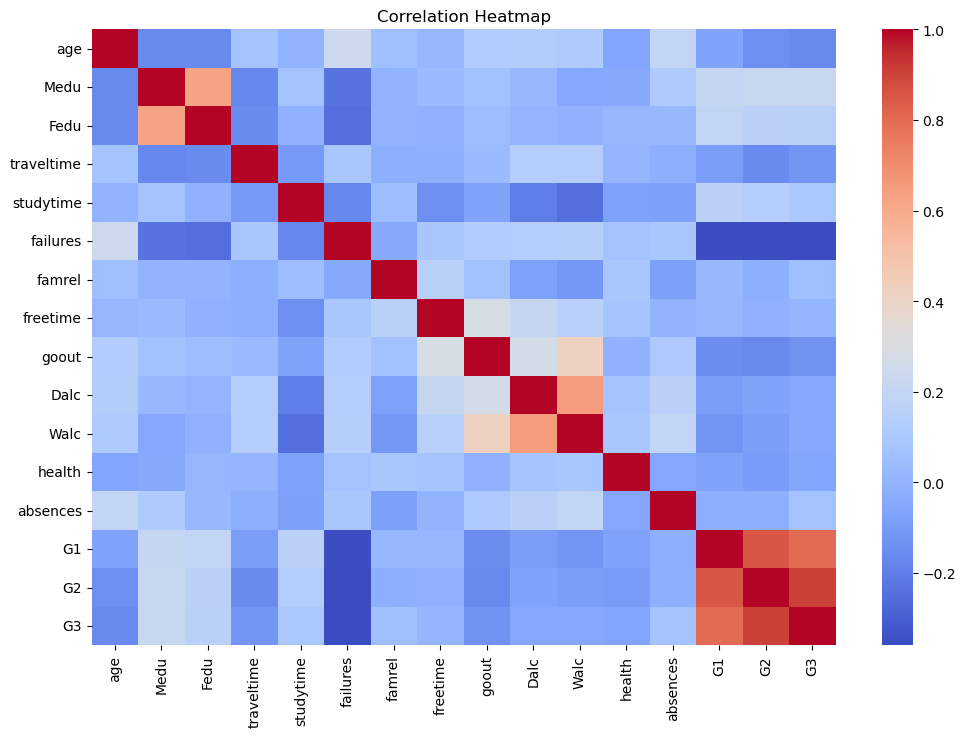

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
absences      0.068030
famrel        0.051363
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

In [196]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

corr['G3'].sort_values(ascending=False)


In [197]:
print("Average G3 by Study Time:")
print(df.groupby('studytime')['G3'].mean())

print("\nAverage G3 by Number of Failures:")
print(df.groupby('failures')['G3'].mean())

print("\nAverage G3 by School Support:")
print(df.groupby('schoolsup')['G3'].mean())


Average G3 by Study Time:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

Average G3 by Number of Failures:
failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64

Average G3 by School Support:
schoolsup
no     10.561047
yes     9.431373
Name: G3, dtype: float64


### Group Comparisons – Interpretation

- **Study Time vs G3:**  
  Students with higher study time (level 3–4) achieve higher final grades (≈11.3) compared to those with lower study time (≈10.0). This supports the hypothesis that more study hours improve performance.

- **Failures vs G3:**  
  There is a clear negative trend: students with no past failures average ≈11.2 in G3, while those with 3 failures average only ≈5.7. This confirms that repeated failures strongly predict poor outcomes.

- **School Support vs G3:**  
  Surprisingly, students receiving school support score slightly lower (≈9.4) than those without (≈10.6). This may be because support is targeted at struggling students, not because support is ineffective.


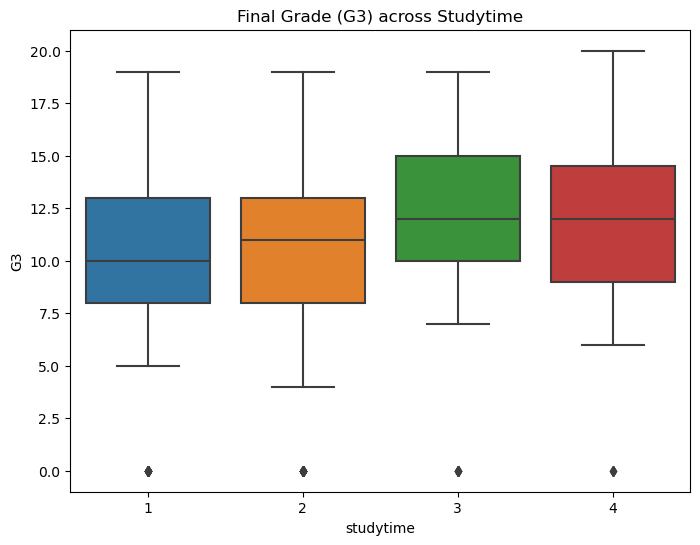

In [198]:
plt.figure(figsize=(8,6))
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("Final Grade (G3) across Studytime")
plt.show()

# Clear trend of higher studytime leading to higher median G3."

# feature engineering

In [199]:
df['attendance_level'] = pd.cut(
    df['absences'],
    bins=[-1, 5, 15, df['absences'].max()],
    labels=['Low', 'Medium', 'High']
)

df['avg_grade'] = df[['G1', 'G2', 'G3']].mean(axis=1)

df['pass'] = (df['G3'] >= 10).astype(int)

def risk_category(g3):
    if g3 < 10:
        return 'High Risk'
    elif g3 < 15:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['risk'] = df['G3'].apply(risk_category)

features_with_g1g2 = df.drop(columns=['pass', 'risk'])
features_no_g1g2 = df.drop(columns=['pass', 'risk', 'G1', 'G2'])

print("Feature engineering completed.")
df[['absences', 'attendance_level', 'avg_grade', 'G1', 'G2', 'G3', 'pass', 'risk']].head()


Feature engineering completed.


,absences,attendance_level,avg_grade,G1,G2,G3,pass,risk
0,6.0,Medium,5.666667,5,6,6,0,High Risk
1,4.0,Low,5.333333,5,5,6,0,High Risk
2,10.0,Medium,8.333333,7,8,10,1,Medium Risk
3,2.0,Low,14.666667,15,14,15,1,Low Risk
4,4.0,Low,8.666667,6,10,10,1,Medium Risk


# Encoding & Scaling 

In [200]:
categorical_cols = df.select_dtypes(include=['object']).columns
numeric_cols = df.select_dtypes(include=[np.number]).columns



# One-hot encoding

In [201]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Convert boolean to int
for col in df_encoded.select_dtypes(include=['bool']).columns:
    df_encoded[col] = df_encoded[col].astype(int)


# Scale numeric columns

In [202]:
scaler = StandardScaler()
df_encoded[numeric_cols] = scaler.fit_transform(df_encoded[numeric_cols])

df_encoded.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes,risk_Low Risk,risk_Medium Risk
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,1,0,0,0,1,1,0,0,0,0
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,0,1,0,0,0,1,1,0,0,0
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,1,0,1,0,1,1,1,0,0,1
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,0,1,1,1,1,1,1,1,1,0
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,0,1,1,0,1,1,0,0,0,1


# Add engineered columns again if needed


In [203]:
df_encoded["G_avg"] = df[["G1", "G2", "G3"]].mean(axis=1)
df_encoded["pass"] = (df["G3"] >= 10).astype(int)

print(df_encoded.dtypes.value_counts())

int32       29
float64     18
category     1
Name: count, dtype: int64


In [204]:
df_encoded["G_avg"] = df[["G1", "G2", "G3"]].mean(axis=1)
df_encoded["pass"] = (df["G3"] >= 10).astype(int)
df_encoded.head()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes,risk_Low Risk,risk_Medium Risk,G_avg
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,0,0,0,1,1,0,0,0,0,5.666667
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,1,0,0,0,1,1,0,0,0,5.333333
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,0,1,0,1,1,1,0,0,1,8.333333
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,1,1,1,1,1,1,1,1,0,14.666667
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,1,1,0,1,1,0,0,0,1,8.666667


In [205]:
X = df_encoded.drop(columns=['pass'])
y = df_encoded['pass']


#  Train/Test Split 

In [206]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (316, 47) Test shape: (79, 47)


#  Logistic Regression 

In [208]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# Logistic Regression with GridSearch
log_reg = LogisticRegression(max_iter=1000, solver='liblinear')

param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2']
}

grid_log = GridSearchCV(log_reg, param_grid, cv=5, scoring='f1')
grid_log.fit(X_train, y_train)

best_log = grid_log.best_estimator_
y_pred_log = best_log.predict(X_test)

print("Logistic Regression Best Params:", grid_log.best_params_)
print(classification_report(y_test, y_pred_log))


ValueError: 
All the 20 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py", line 1151, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py", line 1207, in fit
    X, y = self._validate_data(
           ^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\carnival\AppData\Roaming\Python\Pyt

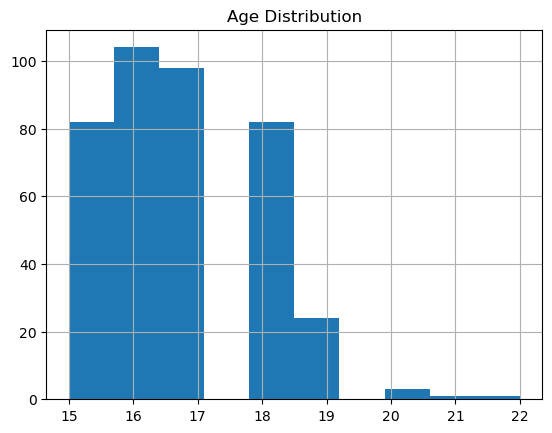

In [ ]:
df["age"].hist(bins=10)
plt.title("Age Distribution")
plt.show()


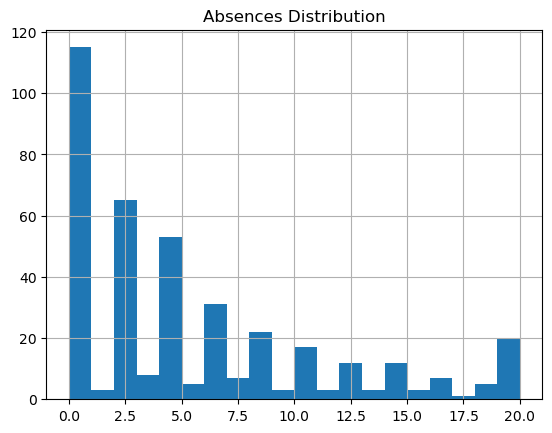

In [ ]:
df["absences"].hist(bins=20)
plt.title("Absences Distribution")
plt.show()


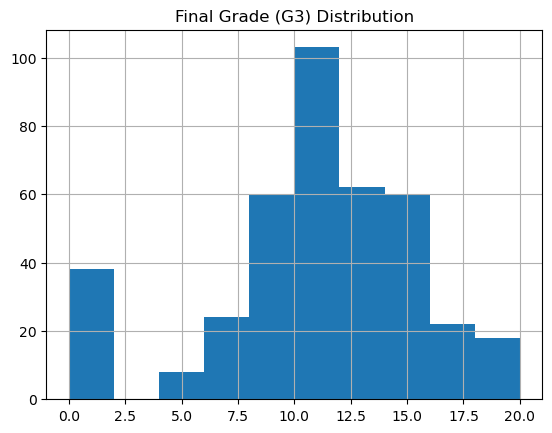

In [ ]:
df["G3"].hist(bins=10)
plt.title("Final Grade (G3) Distribution")
plt.show()


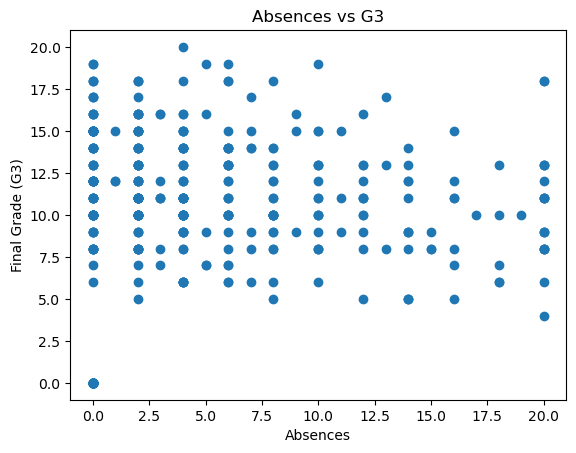

In [ ]:
plt.scatter(df["absences"], df["G3"])
plt.xlabel("Absences")
plt.ylabel("Final Grade (G3)")
plt.title("Absences vs G3")
plt.show()


In [ ]:
features_cluster = ["studytime", "absences", "goout", "freetime"]
X_cluster = df_encoded[features_cluster]

In [ ]:
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)


C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklea

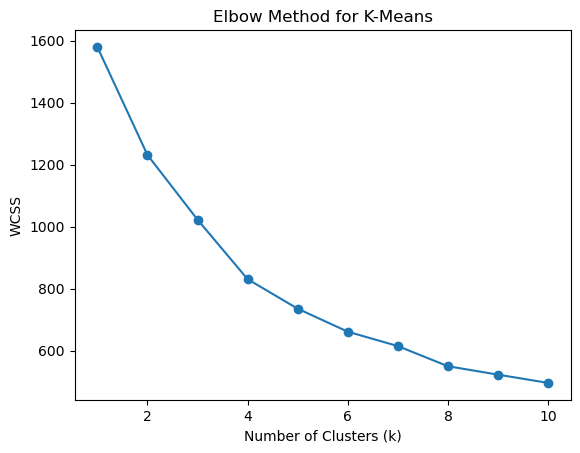

In [ ]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method for K-Means")
plt.show()


C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklea

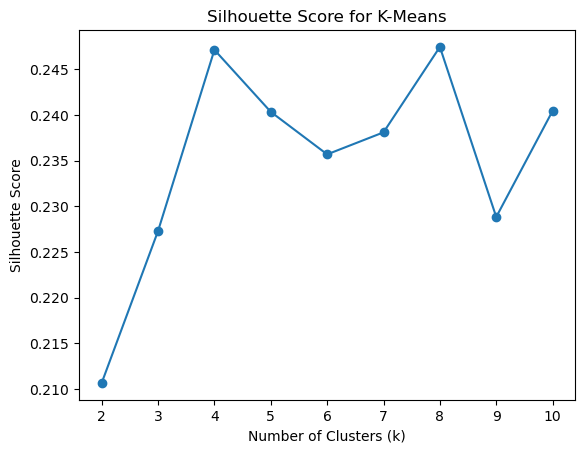

In [ ]:

silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, kmeans.labels_)
    silhouette_scores.append(score)

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_encoded["Cluster"] = kmeans.fit_predict(X_cluster_scaled)

C:\Users\carnival\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


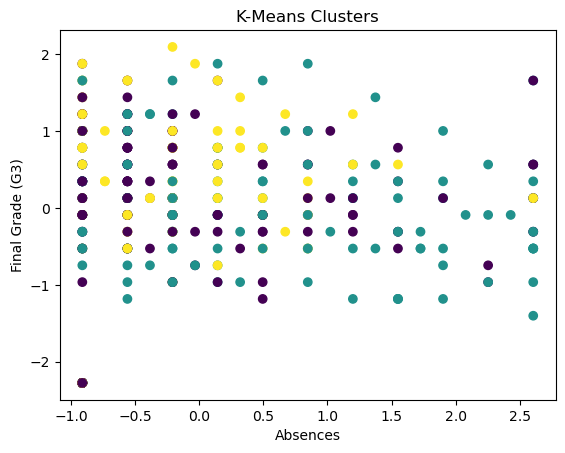

In [ ]:
plt.scatter(df_encoded["absences"], df_encoded["G3"], c=df_encoded["Cluster"], cmap="viridis")
plt.xlabel("Absences")
plt.ylabel("Final Grade (G3)")
plt.title("K-Means Clusters")
plt.show()


# 📝 Conclusion

- The dataset was successfully preprocessed (handling outliers, encoding categorical variables, and scaling features).  
- Exploratory Data Analysis (EDA) showed important patterns:
  - Students with higher study time generally achieved better final grades (G3).
  - High number of absences negatively impacted performance.
  - Some support programs had limited influence on results.  

- In **Clustering**:
  - The Elbow Method and Silhouette Score suggested an optimal number of clusters.
  - K-Means successfully grouped students into clusters with distinct characteristics.
  - Visualization showed clear separation between groups based on absences and final grades.

- **Next Steps**:
  - Evaluate classification models (Logistic Regression, Decision Tree, Random Forest, SVM) to predict student success.  
  - Compare their performance using metrics (accuracy, precision, recall, F1, ROC-AUC).  

Overall, the analysis highlighted that study time and absences are strong predictors of student performance, and clustering revealed meaningful student groups that can help in academic support strategies.


In [ ]:
X = df_encoded.drop("G3", axis=1)
y = np.where(df_encoded["G3"] >= 10, 1, 0)  # 1 = Passed, 0 = Failed

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
print(df_encoded["G3"].value_counts().sort_index())


G3
-2.276226    38
-1.402031     1
-1.183483     7
-0.964934    15
-0.746385     9
-0.527837    32
-0.309288    28
-0.090739    56
 0.127809    47
 0.346358    31
 0.564907    31
 0.783456    27
 1.002004    33
 1.220553    16
 1.439102     6
 1.657650    12
 1.876199     5
 2.094748     1
Name: count, dtype: int64
